In [ ]:
# -*- coding: utf-8 -*-
"""panel4: RAP · (Ωmax,Δ0) 平面 @ V0=20 MHz  (独立程序, 自带物理框架)"""
import numpy as np
from itertools import product
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 字体和输出方式与“2比特ΔΩ.txt”保持一致。

Omega10 = 2*np.pi*100.0
gamma_r = 1.0/540.0
Gamma = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph = 7*Gamma/8
N_step = 600

N = 2
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Ei_factor = n_r*(n_r-1)/2
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')] for s in st])
spont = []
for a in range(N):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items() if s[a] == 'r'])
        spont.append((src, dst))
D_deph = np.zeros((d, d))
for a in range(N):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gamma_deph
ldl = Gamma * n_r
psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)
rr = np.arange(d)
anti = ldl[:, None] + ldl[None, :]

Omega_max_L = 0.048661
t_gate_L = 757.549
D0_L = 0.095775
sD_L = 284.271
sR_L = 105.214
pf_L = 0.500
t_L = (np.arange(N_step)+0.5)*t_gate_L/N_step
t_pi_L = pf_L*t_gate_L
tm_L = np.where(t_L < t_pi_L, t_pi_L/2, t_pi_L + (t_gate_L - t_pi_L)/2)
xR_L = (t_L-tm_L)/sR_L; xD_L = (t_L-tm_L)/sD_L
base_Om_L = -Omega_max_L*np.sqrt(2*np.e)*xR_L*np.exp(-xR_L**2)
base_De_L = D0_L*np.e*xD_L**2*np.exp(-xD_L**2)
dt_L = t_gate_L/N_step
n_pi_L = int(round(pf_L*N_step))

Omega_max_R = 0.0334
t_gate_R = 393.1252
D0_R = 0.0904
sD_R = 392.0985
sR_R = 470.1845
t_R = (np.arange(N_step)+0.5)*t_gate_R/N_step
tau_R_R = sR_R
tau_D_R = sD_R
_a_R = np.exp(-(t_gate_R/(4*tau_R_R))**4)
k_R = np.where(t_R <= t_gate_R/2, 1.0, 2.0)
tk_R = (2.0*k_R - 1.0)*t_gate_R/4.0
sign_R = np.where(k_R == 1.0, 1.0, -1.0)
base_Om_R = Omega_max_R*(np.exp(-((t_R-tk_R)/tau_R_R)**4) - _a_R)/(1.0 - _a_R)
base_De_R = D0_R*sign_R*np.sin(np.pi*(t_R-tk_R)/tau_D_R)
dt_R = t_gate_R/N_step
n_pi_R = N_step//2

def simulate_batch(base_Om, base_De, dt, n_pi, Om, D0, V0):
    B = Om.shape[0]
    drive = base_Om[None, :, None, None] * Om[:, None, None, None] * C[None, None]
    diag_vals = (base_De[None, :, None]*D0[:, None, None]) * n_r[None, None, :] \
                + (V0[:, None, None]*Ei_factor[None, None, :])
    H = drive.copy()
    H[:, :, rr, rr] = diag_vals
    w, v = np.linalg.eigh(H)
    Uh = v * np.exp(-1j*w*dt/2)[:, :, None, :] @ np.swapaxes(v.conj(), -2, -1)
    rho = np.einsum('bi,bj->bij', psi0[None], psi0[None].conj())
    for n in range(N_step):
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        jump = D_deph[None]*rho
        for src, dst in spont:
            jump[:, dst[:, None], dst[None, :]] += Gamma_spont*rho[:, src[:, None], src[None, :]]
        rho = rho + dt*(jump - 0.5*anti[None]*rho)
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        if n == n_pi - 1:
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    F = np.real(np.einsum('i,bij,j->b', psiT.conj(), rho, psiT))
    return F

def scan2(scheme, ax1_vals, ax2_vals, fixed):
    if scheme == 'lcf':
        base_Om, base_De, dt, n_pi = base_Om_L, base_De_L, dt_L, n_pi_L
        Om0, D00 = Omega_max_L, D0_L
    else:
        base_Om, base_De, dt, n_pi = base_Om_R, base_De_R, dt_R, n_pi_R
        Om0, D00 = Omega_max_R, D0_R
    N1, N2 = len(ax1_vals), len(ax2_vals)
    A1, A2 = np.meshgrid(ax1_vals, ax2_vals, indexing='ij')
    if fixed[0] == 'dv':
        Om_fix = fixed[1]
        Om = np.full(A1.size, Om_fix/Om0)
        D0 = A1.ravel()/D00
        V0 = A2.ravel()
    else:
        V0_fix = fixed[1]
        Om = A1.ravel()/Om0
        D0 = A2.ravel()/D00
        V0 = np.full(A1.size, V0_fix)
    F = np.empty(A1.size)
    CH = 256
    for s in range(0, A1.size, CH):
        F[s:s+CH] = simulate_batch(base_Om, base_De, dt, n_pi,
                                   Om[s:s+CH], D0[s:s+CH], V0[s:s+CH])
    return F.reshape(N1, N2)

# ===== panel4: RAP (Ωmax,Δ0) @ V0=20 MHz =====
wg = np.linspace(0.01, 0.12, 45)
d0b = np.linspace(0.02, 0.60, 45)
F = scan2('rap', wg, d0b, ('wd', 0.20))
star = (0.0334, 0.0904); star_color = "magenta"
xlab = r"$\Omega_{max}/2\pi$  (MHz)"; ylab = r"$\Delta_0/2\pi$  (MHz)"
outdir = Path(r"C:\Users\13679\Documents\Codex\2026-10-09\fan\outputs")
outdir.mkdir(parents=True, exist_ok=True)
fname = "bell_panel4_RAP_wd"

fig, ax = plt.subplots(figsize=(10, 8))
Fp = np.where(np.isfinite(F), np.minimum(F, 1.0), np.nan)
fmin, fmax = np.nanmin(Fp), np.nanmax(Fp)
cmap_ref = LinearSegmentedColormap.from_list("ref_yor", [
    (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
cf = ax.contourf(wg*100, d0b*100, Fp.T,
                 levels=np.linspace(fmin, fmax, 28), cmap=cmap_ref)
cl = np.linspace(fmin, fmax, 5)[1:-1]
cs = ax.contour(wg*100, d0b*100, Fp.T, levels=cl,
                colors="k", linewidths=1.15)
ax.clabel(cs, fmt="%.4f", fontsize=30, inline=True, inline_spacing=5,
          manual=[(2.5, 30.0), (5.5, 25.0), (9.0, 32.0)])
cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                  pad=0.025, fraction=0.055, aspect=24)
cb.ax.tick_params(labelsize=30, width=1.4, length=6)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
ax.plot(star[0]*100, star[1]*100, "*", ms=18, color="k", mec=star_color, mew=1.5)
ax.set_xlabel(xlab, fontsize=30); ax.set_ylabel(ylab, fontsize=30)
ax.tick_params(axis="both", labelsize=30, width=1.4, length=6)
for sp in ax.spines.values(): sp.set_linewidth(1.4)
fig.tight_layout()
fig.savefig(outdir/f"{fname}.png", dpi=200)
fig.savefig(outdir/f"{fname}.pdf")
print("saved", outdir/f"{fname}.png", outdir/f"{fname}.pdf")


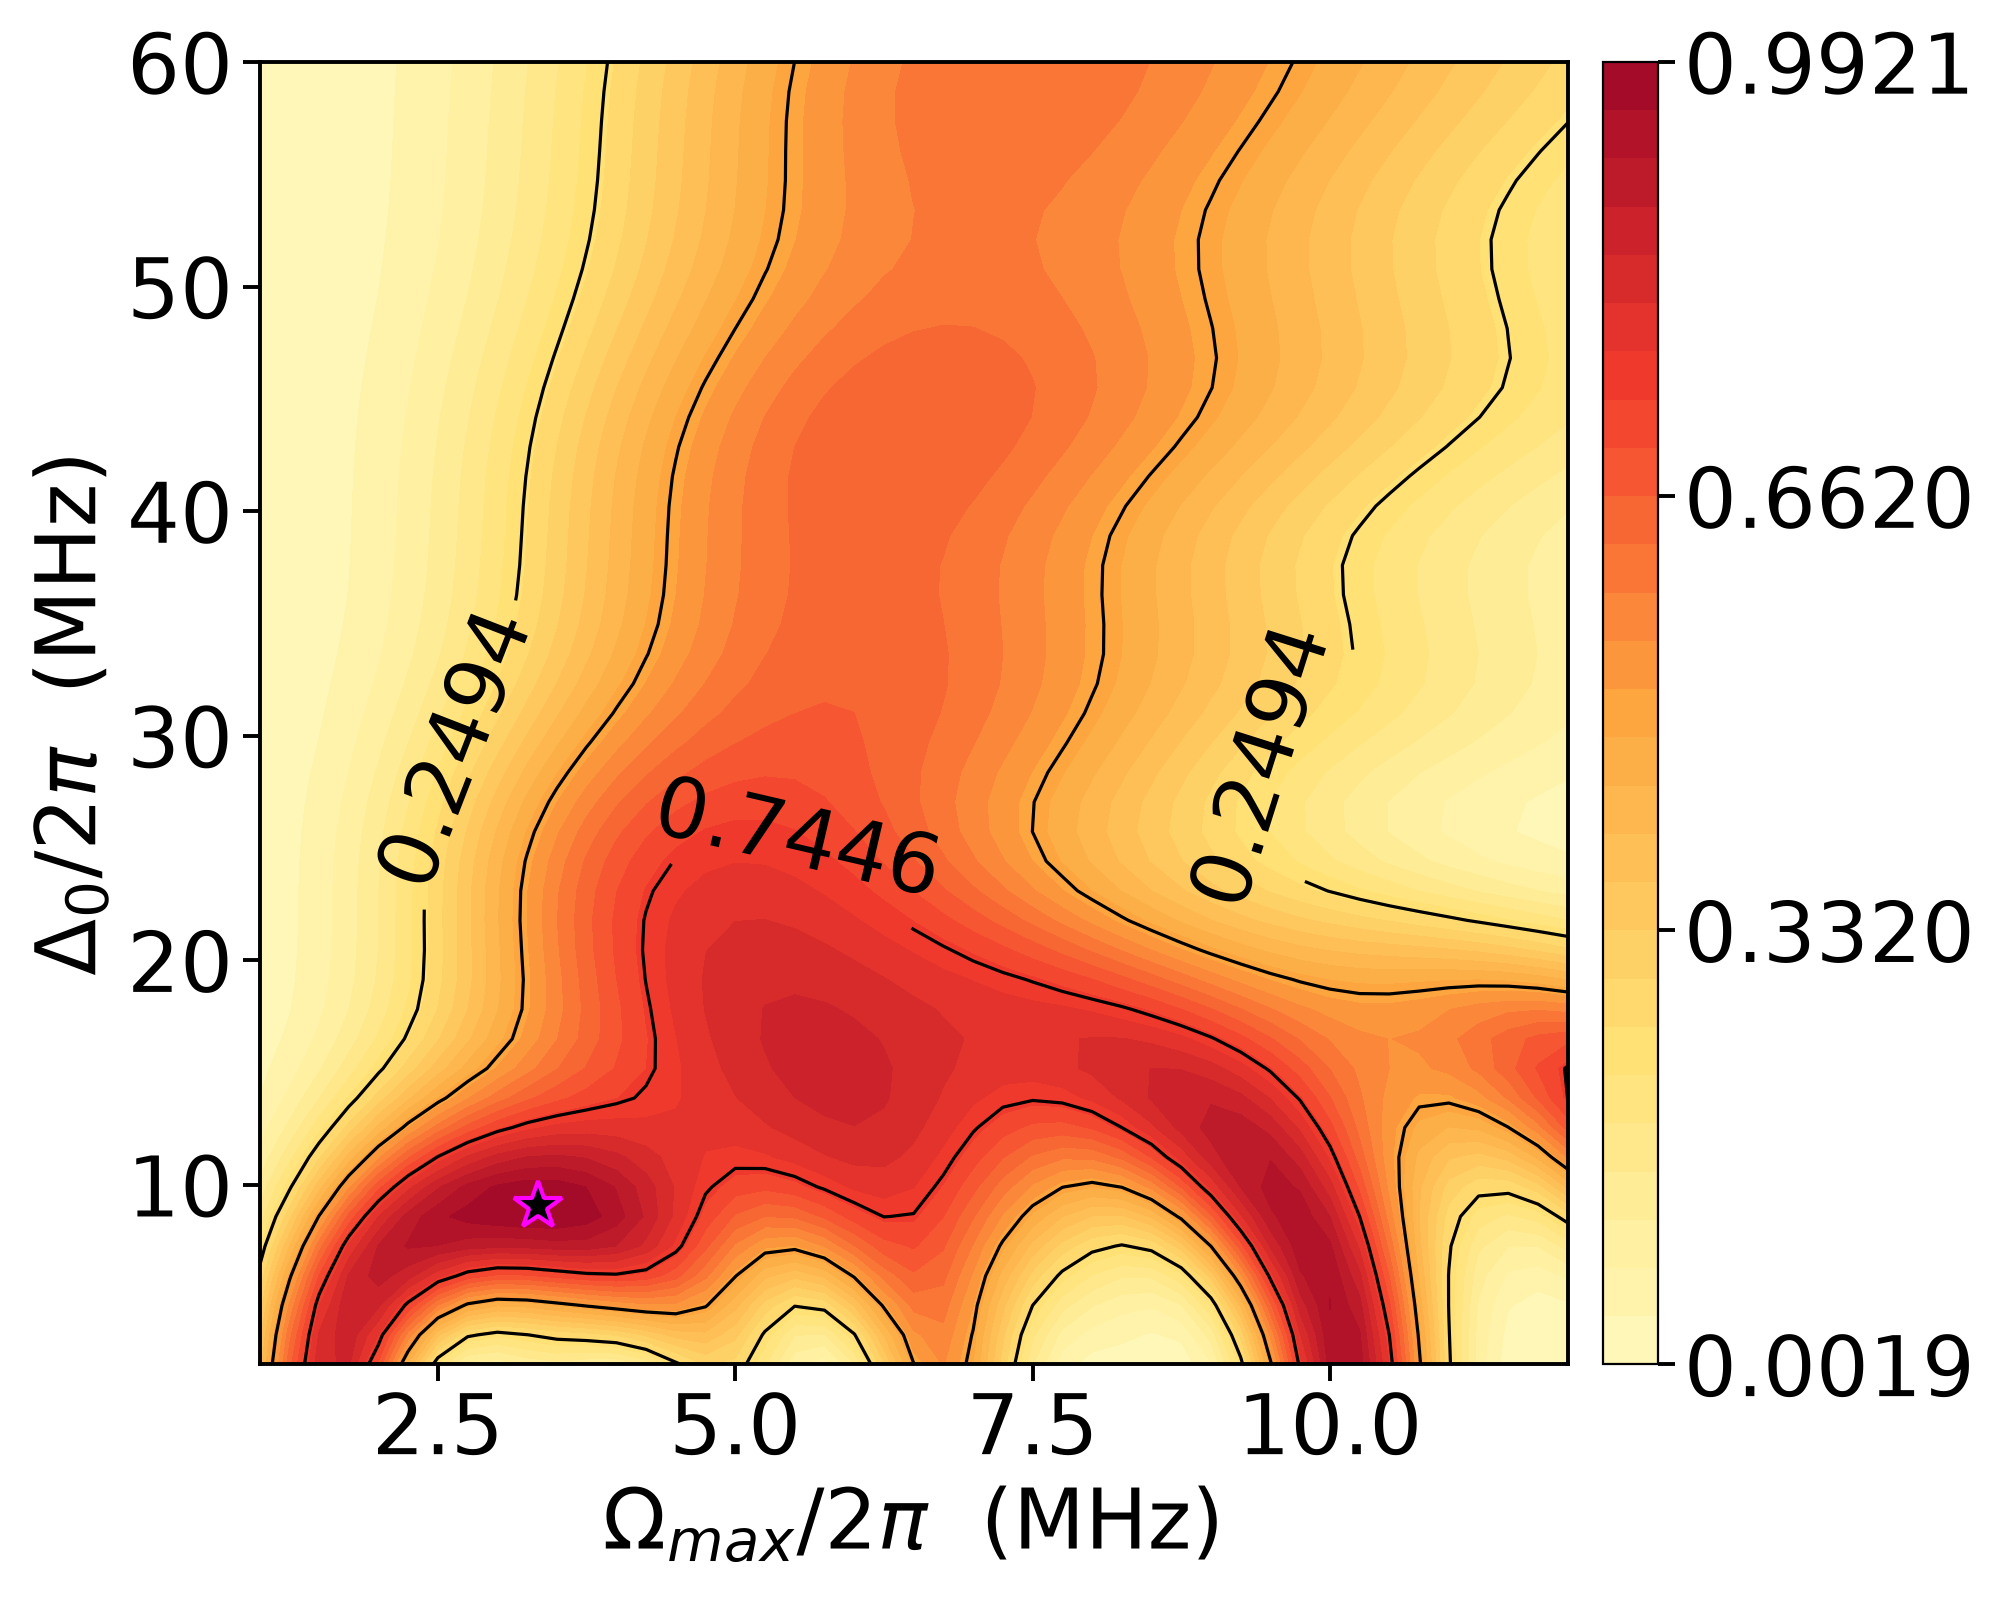


In [ ]:
# -*- coding: utf-8 -*-
"""3 比特 W 态 RAP: (Omega_max, Delta_max) 平面，V0 固定为最优值

坐标范围与 3/4 比特图一致，样式与 4 比特图一致：
10x8 英寸、字体 30、颜色标尺 4 个刻度、无标题、不标注 Fidelity。
本文件完全独立，只依赖 numpy 与 matplotlib。

用法:  python 3ARAPOD.py           已有 npz 则直接出图
       python 3ARAPOD.py rescan    强制重新扫描
"""
import os
import sys
import time
from itertools import product

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# ===================== 物理内核: 3 比特 Lindblad 主方程 (27 维) =====================
# 时间以 Omega10 = 2*pi*100 MHz 为单位; 频率同理 (x100 = MHz)
OMEGA10      = 2.0 * np.pi * 100.0
GAMMA        = (1.0 / 540.0) / OMEGA10
GAMMA_SPONT  = GAMMA / 16.0
GAMMA_DEPH   = 7.0 * GAMMA / 8.0

NATOM  = 3
STATES = ["".join(s) for s in product("01r", repeat=NATOM)]
IDX    = {s: i for i, s in enumerate(STATES)}
DIM    = len(STATES)

COUPLING = np.zeros((DIM, DIM), dtype=complex)
for s, i in IDX.items():
    for a in range(NATOM):
        if s[a] == "1":
            tgt = s[:a] + "r" + s[a + 1:]
        elif s[a] == "r":
            tgt = s[:a] + "1" + s[a + 1:]
        else:
            continue
        COUPLING[IDX[tgt], i] = 0.5

N_R       = np.array([s.count("r") for s in STATES], dtype=float)
N_R_PAIRS = N_R * (N_R - 1.0) / 2.0
DIAG      = np.arange(DIM)
SWAP      = np.array([IDX[s.replace("0", "_").replace("1", "0").replace("_", "1")]
                      for s in STATES])

PSI0 = np.zeros(DIM, dtype=complex)
PSI0[IDX["111"]] = 1.0
PSIT = np.zeros(DIM, dtype=complex)
for a in range(NATOM):
    s = ["0"] * NATOM
    s[a] = "1"
    PSIT[IDX["".join(s)]] = 1.0 / np.sqrt(NATOM)

SPONT = []
for a in range(NATOM):
    for ch in "01":
        src = np.array([i for s, i in IDX.items() if s[a] == "r"])
        dst = np.array([IDX[s[:a] + ch + s[a + 1:]]
                        for s, i in IDX.items() if s[a] == "r"])
        SPONT.append((src, dst))

DEPH_JUMP = np.zeros((DIM, DIM))
for a in range(NATOM):
    m = np.array([1.0 if s[a] == "r" else 0.0 for s in STATES])
    DEPH_JUMP += np.outer(m, m)
DEPH_JUMP *= GAMMA_DEPH
ANTICOM = GAMMA * (N_R[:, None] + N_R[None, :])


def envelopes(kind, tau, wR, wD, d0, om0, pf, nstep):
    """返回 (B, nstep) 的 Omega(t)、Delta(t) 与 pi 门所在步。"""
    tau = tau[:, None]
    t = (np.arange(nstep)[None, :] + 0.5) * tau / nstep
    if kind == "lcf":
        tpi = pf[:, None] * tau
        tm = np.where(t < tpi, tpi / 2.0, tpi + (tau - tpi) / 2.0)
        xr = (t - tm) / wR[:, None]
        xd = (t - tm) / wD[:, None]
        om = -om0[:, None] * np.sqrt(2.0 * np.e) * xr * np.exp(-xr ** 2)
        de = d0[:, None] * np.e * xd ** 2 * np.exp(-xd ** 2)
        swap = np.round(pf * nstep).astype(int)
    else:
        edge = np.exp(-((tau / (4.0 * wR[:, None])) ** 4))
        half = np.where(t <= tau / 2.0, 1.0, 2.0)
        tk = (2.0 * half - 1.0) * tau / 4.0
        sgn = np.where(half == 1.0, 1.0, -1.0)
        den = np.maximum(1.0 - edge, 1e-10)
        om = om0[:, None] * (np.exp(-((t - tk) / wR[:, None]) ** 4) - edge) / den
        de = d0[:, None] * sgn * np.sin(np.pi * (t - tk) / wD[:, None])
        swap = np.full(tau.shape[0], nstep // 2, dtype=int)
    return om, de, swap


def fidelity_batch(kind, P, nstep=220):
    """P: (B, 7) = [tau, tauR, tauD, Dmax, V0, Omax, PF]，返回 (B,) 保真度。"""
    P = np.atleast_2d(np.asarray(P, dtype=float))
    B = P.shape[0]
    tau, wR, wD, d0, v0, om0, pf = [P[:, i].copy() for i in range(7)]
    om, de, swap = envelopes(kind, tau, wR, wD, d0, om0, pf, nstep)
    H = om[:, :, None, None] * COUPLING[None, None, :, :]
    H[:, :, DIAG, DIAG] += (de[:, :, None] * N_R[None, None, :]
                            + v0[:, None, None] * N_R_PAIRS[None, None, :])
    w, v = np.linalg.eigh(H.reshape(-1, DIM, DIM))
    v = v.reshape(B, nstep, DIM, DIM)
    dt = tau / nstep
    phase = np.exp(-1j * w.reshape(B, nstep, 1, DIM)
                   * (0.5 * dt)[:, None, None, None])
    half = (v * phase) @ np.swapaxes(v.conj(), 2, 3)
    rho = np.zeros((B, DIM, DIM), dtype=complex)
    rho[:, IDX["111"], IDX["111"]] = 1.0
    for n in range(nstep):
        u = half[:, n]
        rho = u @ rho @ u.conj().transpose(0, 2, 1)
        jump = DEPH_JUMP[None] * rho
        for src, dst in SPONT:
            jump[:, dst[:, None], dst[None, :]] += \
                GAMMA_SPONT * rho[:, src[:, None], src[None, :]]
        rho += dt[:, None, None] * (jump - 0.5 * ANTICOM[None] * rho)
        rho = u @ rho @ u.conj().transpose(0, 2, 1)
        sel = np.where(n == swap - 1)[0]
        if sel.size:
            rho[sel] = rho[sel][:, SWAP, :][:, :, SWAP]
    return np.real(np.einsum("i,bij,j->b", PSIT.conj(), rho, PSIT))



# ===================== 本面板参数 =====================
KIND    = "rap"
TAU     = 925.3818     # 归一化门时间 (x0.15915 = ns)
TAUR    = 280.2858     # 上升段
TAUD    = 624.8365     # 下降段
D0_OPT  = 0.072657      # 最优 Delta_max (x100 = MHz)
V0_OPT  = 0.200000      # 最优 V0 (x100 = MHz)
OM_OPT  = 0.036328      # 最优 Omega_max (x100 = MHz)
PF      = 0.500000      # LCF 中点 pi 门占比
F_PEAK  = 0.998903   # 该方案中心保真度
F_WORST = 0.973155  # 该方案 +-5% 最坏保真度

OUTDIR = os.path.dirname(os.path.abspath(__file__))
NPZ    = os.path.join(OUTDIR, "w3_rap_wd_grid.npz")
PNG    = os.path.join(OUTDIR, "W3_RAP_Omega_Delta.png")
CHUNK  = 16              # 每批并行传播的点数
NSTEP  = 220             # 传播步数 (哈密顿量部分精确对角化, 耗散一阶)
M      = 41              # 每方向网格数


def grid(a, b, n, extra):
    """与 3/4 比特图相同的坐标范围 + 最优点补点 (去重排序)。"""
    return np.unique(np.round(np.concatenate(
        [np.linspace(a, b, n), np.asarray(extra, float)]), 6))


def scan():
    t0 = time.time()
    base = np.array([TAU, TAUR, TAUD, D0_OPT, V0_OPT, OM_OPT, PF])
    a1 = grid(1.0, 12.0, M, [OM_OPT * 100.0])      # Omega_max (MHz)
    a2 = grid(2.0, 60.0, M, [D0_OPT * 100.0])      # Delta_max (MHz)
    A1, A2 = np.meshgrid(a1, a2, indexing="ij")
    flat = np.empty(A1.size)
    for i in range(0, A1.size, CHUNK):
        sl = slice(i, min(i + CHUNK, A1.size))
        P = np.tile(base, (sl.stop - sl.start, 1))
        P[:, 5] = A1.ravel()[sl] / 100.0
        P[:, 3] = A2.ravel()[sl] / 100.0
        flat[sl] = fidelity_batch(KIND, P, nstep=NSTEP)
    F = flat.reshape(A1.shape)
    print("[rap-wd] grid=%s pts=%d 用时 %.0fs Fmax=%.6f" %
          (F.shape, F.size, time.time() - t0, np.nanmax(F)), flush=True)
    star = np.array([OM_OPT*100.0, D0_OPT*100.0])
    np.savez(NPZ, a1=A1, a2=A2, F=F, star=star)
    return A1, A2, F, star


def plot(X, Y, F, star):
    fmin, fmax = float(np.nanmin(F)), float(np.nanmax(F))
    cmap = LinearSegmentedColormap.from_list("ref_yor", [
        (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
        (0.624, 0.031, 0.157),
    ])
    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(X, Y, F, levels=np.linspace(fmin, fmax, 28), cmap=cmap)
    lines = np.linspace(fmin, fmax, 9)[1:-1]
    cs = ax.contour(X, Y, F, levels=lines, colors="black", linewidths=1.15)
    ax.clabel(cs, fmt="%.3f", fontsize=30, inline=True, inline_spacing=4,
              manual=[(2.8, 38.0), (5.6, 44.0), (8.8, 34.0)])
    ax.plot(star[0], star[1], "*", ms=15, color="black",
            markeredgecolor="lime", markeredgewidth=1.2)
    cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                      pad=0.025, fraction=0.055, aspect=24)
    cb.ax.tick_params(labelsize=30, width=1.4, length=6)
    cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
    cb.outline.set_linewidth(1.3)
    ax.set_xlabel(r"$\Omega_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.set_ylabel(r"$\Delta_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.set_xlim(1.0, 12.0)
    ax.set_ylim(2.0, 60.0)
    ax.tick_params(axis="both", labelsize=30, width=1.35, length=5.5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.35)
    fig.tight_layout()
    fig.savefig(PNG, dpi=200)
    plt.close(fig)
    print("saved " + PNG)


if __name__ == "__main__":
    force = (len(sys.argv) > 1 and sys.argv[1] == "rescan")
    if os.path.exists(NPZ) and not force:
        d = np.load(NPZ)
        X, Y, F, star = d["a1"], d["a2"], d["F"], d["star"]
        print("loaded " + NPZ)
    else:
        X, Y, F, star = scan()
    plot(X, Y, F, star)


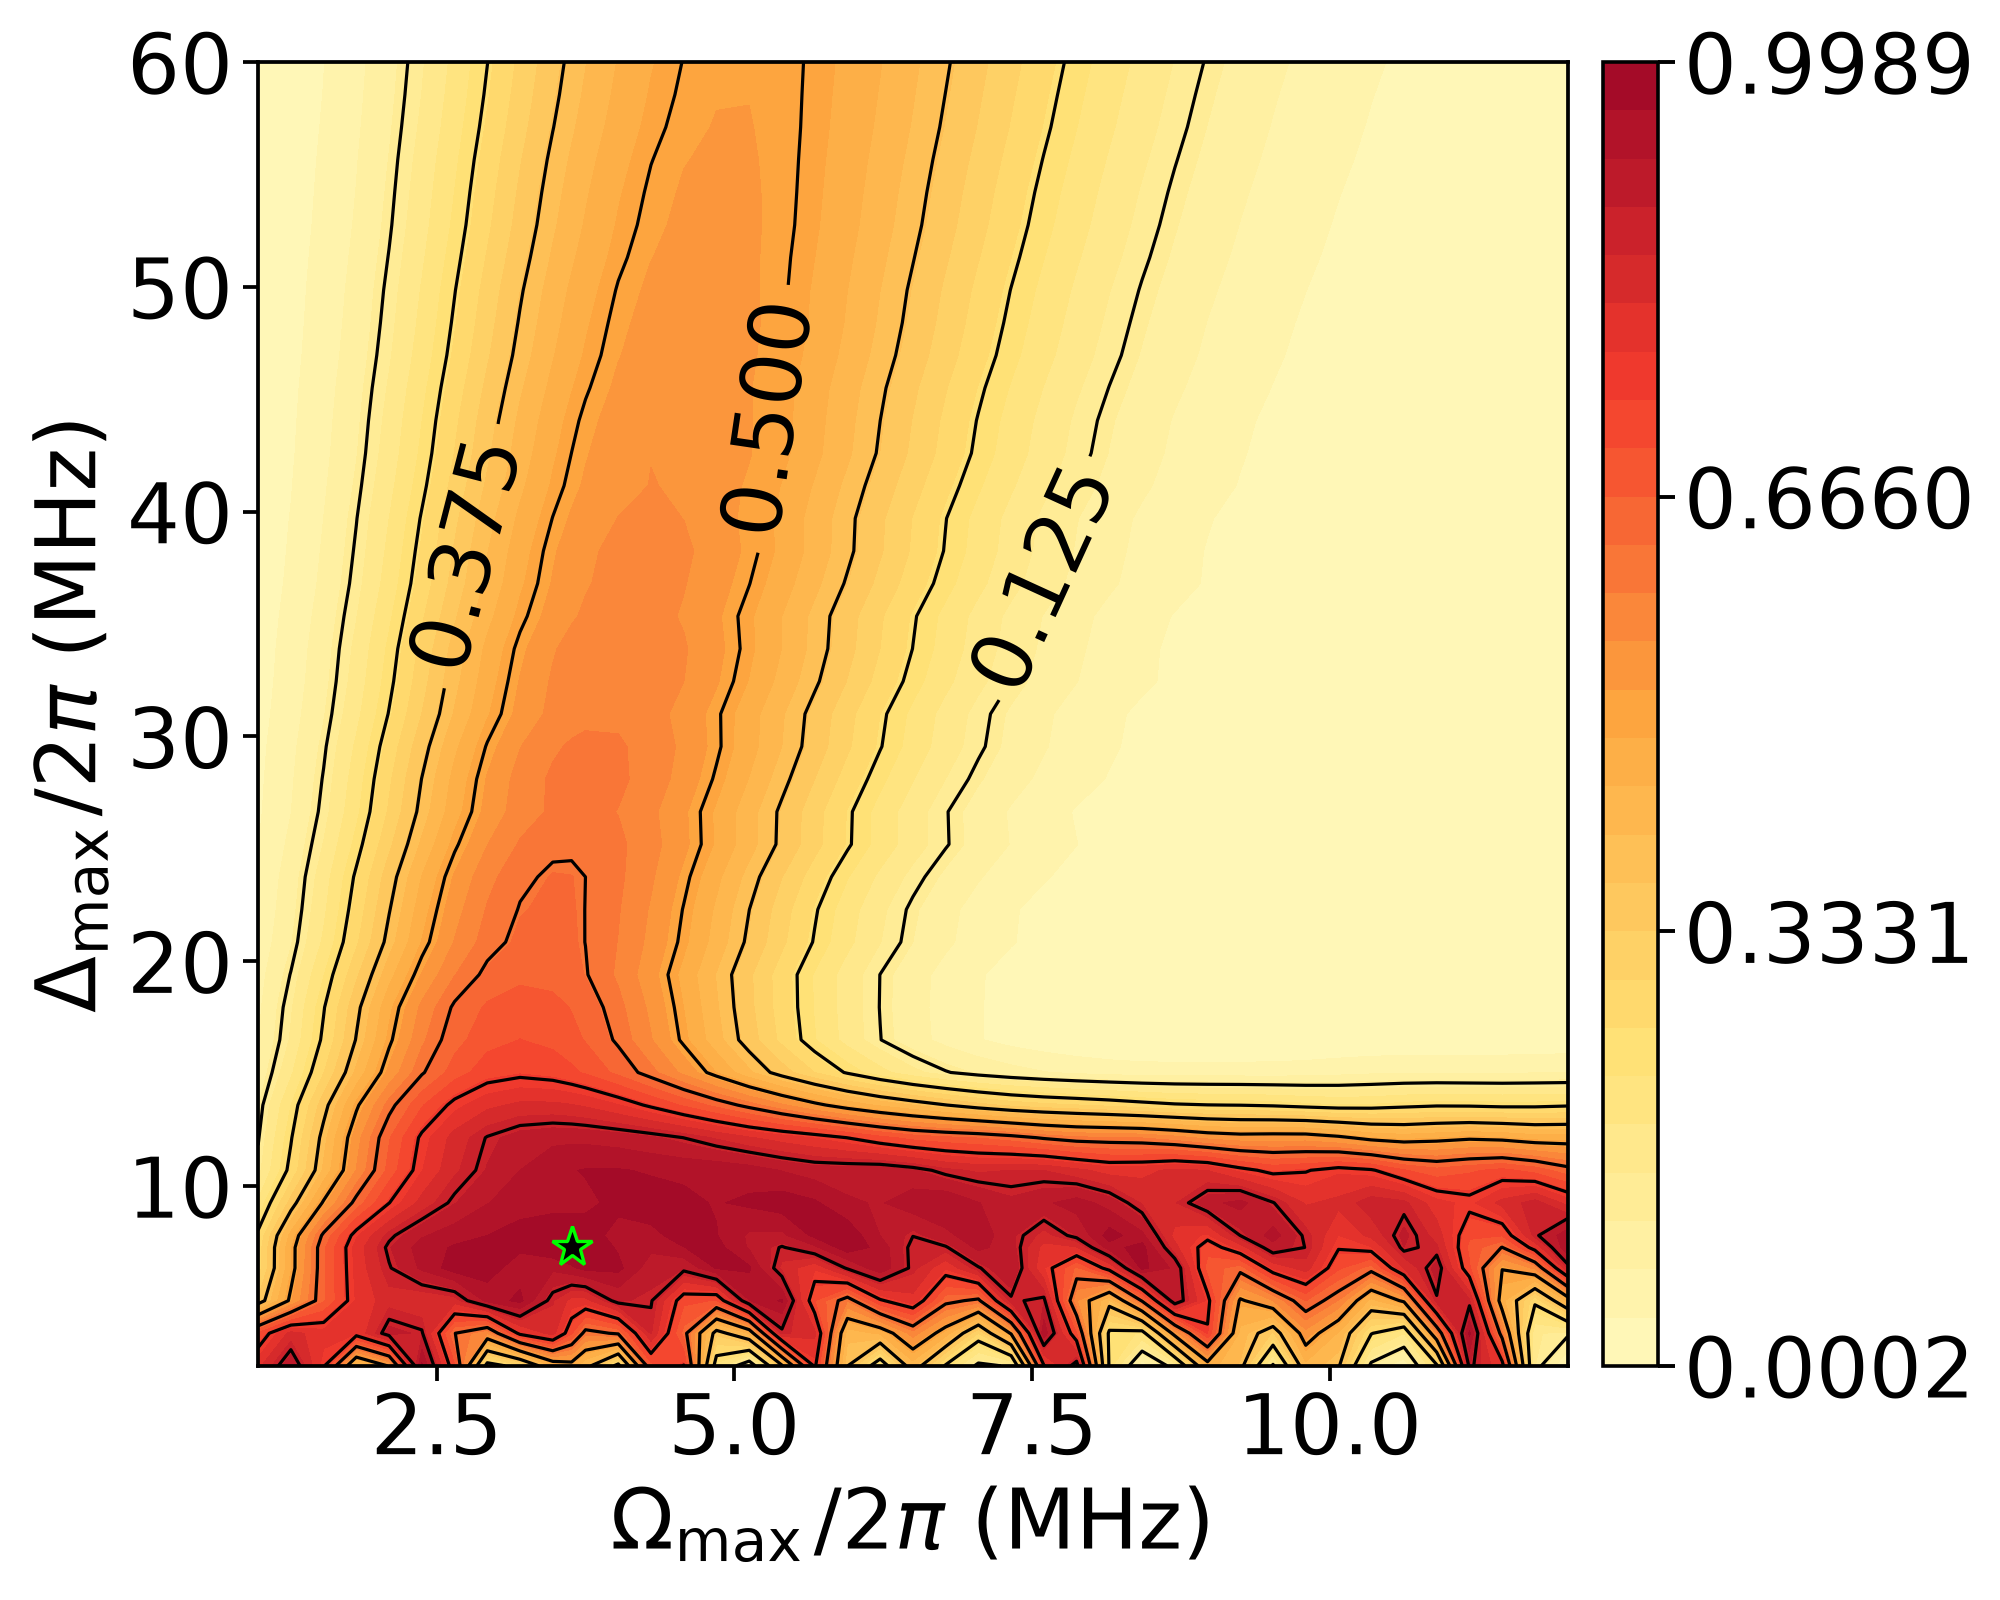


In [ ]:
# -*- coding: utf-8 -*-
"""RAP 面板: (Omega_max, Delta_0) 平面, V_0 = 20 MHz 固定
坐标范围与 3 比特图一致: Omega_max in [1,12] MHz, Delta_0 in [2,60] MHz

用法:
  python w4_panel_rap_wd.py           已有 w4_p3b_rap_wd.npz 则直接出图, 否则先扫描
  python w4_panel_rap_wd.py rescan    强制重新扫描
本文件完全独立, 只依赖 numpy 与 matplotlib (不需要 w4_core.py / w4_like3.py)。
"""
import os, sys, time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ===================== 物理内核: 4 比特 Lindblad 主方程 =====================
# 单位: 频率以 Omega0 = 2*pi*100 MHz 为标度; 时间以 us
Omega0       = 2.0 * np.pi * 100.0
gamma_r      = 1.0 / 540.0                 # Rydberg 寿命 (us)
Gamma_spont  = gamma_r / 16.0
Gamma_deph   = 7.0 * gamma_r / 8.0

# ---- 81 维 Hilbert 空间 (每比特 0 / 1 / r) ----
states = [q1 + q2 + q3 + q4
          for q1 in "01r" for q2 in "01r" for q3 in "01r" for q4 in "01r"]
dim = len(states)
si  = {s: i for i, s in enumerate(states)}
nr  = np.array([s.count("r") for s in states], dtype=float)

pairs = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
int_rel = np.zeros(dim)
for i, s in enumerate(states):
    rm = np.array([c == "r" for c in s])
    for a, b in pairs:
        if rm[a] and rm[b]:
            int_rel[i] += 1.0

# 驱动耦合 |1><r| + |r><1|
ci, cj = [], []
for i, s in enumerate(states):
    for p in range(4):
        if s[p] == "1":
            ci.append(i); cj.append(si[s[:p] + "r" + s[p + 1:]])
        elif s[p] == "r":
            ci.append(i); cj.append(si[s[:p] + "1" + s[p + 1:]])
ci = np.array(ci); cj = np.array(cj)

# 中点 pi 门比特翻转 0<->1
fm = np.zeros(dim, dtype=int)
for s, idx in si.items():
    fm[idx] = si[s.replace("0", "_").replace("1", "0").replace("_", "1")]

i1111 = si["1111"]
iW    = np.array([si[s] for s in ["1000", "0100", "0010", "0001"]], dtype=int)

# 第 k 个比特处于 |r> 的指示量
mr = [np.zeros(dim, dtype=float) for _ in range(4)]
for k in range(4):
    for i, s in enumerate(states):
        if s[k] == "r":
            mr[k][i] = 1.0

# 自发辐射 jump 的 preimage (gather 版, 等价于 matmul 版)
g0 = np.full((4, dim), -1, dtype=int)
g1 = np.full((4, dim), -1, dtype=int)
for k in range(4):
    for i, s in enumerate(states):
        c = s[k]
        if c == "0":
            g0[k, i] = si[s[:k] + "r" + s[k + 1:]]
        elif c == "1":
            g1[k, i] = si[s[:k] + "r" + s[k + 1:]]


def build_H(O, D, V0):
    """O, D, V0: 形状 (B,) 的物理量; 返回 H (B, dim, dim)。"""
    B = O.shape[0]
    H = np.zeros((B, dim, dim), dtype=complex)
    diag = nr[None, :] * D[:, None] + int_rel[None, :] * V0[:, None]
    idxr = np.arange(dim)
    H[:, idxr, idxr] = diag
    H[:, ci, cj] = O[:, None] / 2.0
    return H


def L_rhs(rho):
    """Lindblad 右端 (不含 dt); rho 形状 (B, dim, dim)。"""
    out = np.zeros_like(rho)
    for k in range(4):
        d = mr[k]
        out -= 0.5 * (Gamma_deph + Gamma_spont) * (
            d[:, None] * rho + rho * d[None, :])
    for k in range(4):
        d = mr[k]
        out += Gamma_deph * np.einsum("i,j,bij->bij", d, d, rho)
    for k in range(4):
        g = g0[k]; ok = g >= 0; p = np.where(ok)[0]
        out[:, p, :][:, :, p] += Gamma_spont * rho[:, g[p], :][:, :, g[p]]
    for k in range(4):
        g = g1[k]; ok = g >= 0; p = np.where(ok)[0]
        out[:, p, :][:, :, p] += Gamma_spont * rho[:, g[p], :][:, :, g[p]]
    return out


# ---- 脉冲包络 ----
def lcf_env(t, t_gate, sR, sD, PF):
    tpi = PF * t_gate
    tm = np.where(t <= tpi, tpi / 2.0, tpi + (t_gate - tpi) / 2.0)
    xR = (t - tm) / sR
    xD = (t - tm) / sD
    return (-np.sqrt(2 * np.e) * xR * np.exp(-xR ** 2),
            np.e * xD ** 2 * np.exp(-xD ** 2))


def rap_env(t, t_gate, tau_R, tau_D):
    _a = np.exp(-(t_gate / (4.0 * tau_R)) ** 4)
    k = np.where(t <= t_gate / 2.0, 1.0, 2.0)
    tk = (2.0 * k - 1.0) * t_gate / 4.0
    sign = np.where(k == 1.0, 1.0, -1.0)
    return ((np.exp(-((t - tk) / tau_R) ** 4) - _a) / (1.0 - _a),
            sign * np.sin(np.pi * (t - tk) / tau_D))


def env_at(t, pulse_type, p):
    if pulse_type == "lcf":
        return lcf_env(t, p["t_gate"], p["sR"], p["sD"], p["PF"])
    return rap_env(t, p["t_gate"], p["tau_R"], p["tau_D"])


def simulate(pulse_type, p, Omega_arr, D0_arr, V0_arr, n_steps=700):
    """RK4 积分主方程, 批处理 B 个参数点; 返回保真度 (B,)"""
    Omega_arr = np.asarray(Omega_arr, float)
    D0_arr    = np.asarray(D0_arr, float)
    V0_arr    = np.asarray(V0_arr, float)
    B = Omega_arr.size
    t_gate = p["t_gate"]
    dt = t_gate / n_steps
    rho = np.zeros((B, dim, dim), dtype=complex)
    rho[:, i1111, i1111] = 1.0
    n_half = n_steps // 2
    applied = False
    for n in range(n_steps):
        t0 = n * dt
        e1 = env_at(t0, pulse_type, p)
        H1 = build_H(e1[0] * Omega_arr, e1[1] * D0_arr, V0_arr)
        k1 = -1j * (H1 @ rho - rho @ H1) + L_rhs(rho)
        rho2 = rho + 0.5 * dt * k1
        e2 = env_at(t0 + 0.5 * dt, pulse_type, p)
        H2 = build_H(e2[0] * Omega_arr, e2[1] * D0_arr, V0_arr)
        k2 = -1j * (H2 @ rho2 - rho2 @ H2) + L_rhs(rho2)
        rho3 = rho + 0.5 * dt * k2
        k3 = -1j * (H2 @ rho3 - rho3 @ H2) + L_rhs(rho3)
        rho4 = rho + dt * k3
        e4 = env_at(t0 + dt, pulse_type, p)
        H4 = build_H(e4[0] * Omega_arr, e4[1] * D0_arr, V0_arr)
        k4 = -1j * (H4 @ rho4 - rho4 @ H4) + L_rhs(rho4)
        rho = rho + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        if (not applied) and n == n_half - 1:
            rho = rho[:, fm, :][:, :, fm]
            applied = True
    return np.real(np.sum(rho[:, iW, :][:, :, iW], axis=(1, 2)) / 4.0)

# ===================== 本面板参数 =====================
KIND    = "rap"
TAU     = 394.6934   # 归一化门时间
TAUR    = 496.3033   # 上升段
TAUD    = 463.4327   # 下降段
D0_OPT  = 0.0853     # 最优失谐 (归一化, x100 = MHz)
OM_OPT  = 0.0267     # 最优 Omega_max (归一化, x100 = MHz)
V0_FIX  = 0.20       # 里德堡阻塞 (20 MHz)
F_PEAK  = 0.9990026  # 参考: 该方案峰值保真度
F_WORST = 0.9839040  # 参考: +-5% 噪声最坏保真度

OUTDIR = os.path.dirname(os.path.abspath(__file__))
NPZ   = os.path.join(OUTDIR, "w4_p3b_rap_wd_fast.npz")
PNG   = os.path.join(OUTDIR, "W4_RAP_Omega_Delta.png")
CHUNK = 120
FAST_FACTOR = 2.5

def grid(a, b, n, extra):
    """与 3 比特图相同的坐标范围 + 最优点附近补点 (去重排序)"""
    return np.unique(np.round(np.concatenate(
        [np.linspace(a, b, n), np.asarray(extra, float)]), 6))


def F_batch(tau, tauR, tauD, Om_list, D0_list, V0_list, ns):
    """Om / D0 / V0 以归一化比值输入, 内部换算到物理单位"""
    if KIND == "lcf":
        p = {"t_gate": tau / Omega0, "sR": tauR / Omega0,
             "sD": tauD / Omega0, "PF": 0.5}
    else:
        p = {"t_gate": tau / Omega0, "tau_R": tauR / Omega0,
             "tau_D": tauD / Omega0}
    F = simulate(KIND, p, np.asarray(Om_list, float) * Omega0,
                 np.asarray(D0_list, float) * Omega0,
                 np.asarray(V0_list, float) * Omega0, n_steps=ns)
    F = np.nan_to_num(np.real(F), nan=-1.0)
    return np.where((F >= 0) & (F <= 1.0), F, -1.0)


def scan():
    """(Omega_max, Delta0) 平面扫描, V0 固定 20 MHz"""
    t0 = time.time()
    om_opt = OM_OPT * 100.0
    a1 = grid(1.0, 12.0, 13,
              [om_opt + d for d in (-0.30, -0.15, 0.0, 0.15, 0.30)])  # Ommax (MHz)
    a2 = grid(2.0, 60.0, 13, [D0_OPT * 100.0])                        # Delta0 (MHz)
    A1, A2 = np.meshgrid(a1, a2, indexing="ij")
    ns = int(max(600, FAST_FACTOR * max(V0_FIX, a1.max() / 100.0,
                                a2.max() / 100.0) * TAU))
    flat = np.full(A1.size, np.nan)
    for i in range(0, A1.size, CHUNK):
        sl = slice(i, min(i + CHUNK, A1.size))
        flat[sl] = F_batch(TAU, TAUR, TAUD, A1.ravel()[sl] / 100.0,
                           A2.ravel()[sl] / 100.0,
                           np.full(sl.stop - sl.start, V0_FIX), ns)
    F = np.where(flat < 0, np.nan, flat).reshape(A1.shape)
    print(f"[{KIND}-wd] grid={A1.shape} ns={ns} pts={F.size} "
          f"用时 {time.time()-t0:.0f}s Fmax={np.nanmax(F):.6f} "
          f"无效={int(np.isnan(F).sum())}", flush=True)
    star = np.array([D0_OPT * 100.0, om_opt])
    np.savez(NPZ, a1=A1, a2=A2, F=F, star=star)
    return A1, A2, F, star


def plot(X, Y, F, star):
    Fp = np.where(np.isfinite(F), np.minimum(F, 1.0), np.nan)
    fmin, fmax = np.nanmin(Fp), np.nanmax(Fp)
    cmap = LinearSegmentedColormap.from_list("ref_yor", [
        (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
        (0.624, 0.031, 0.157),
    ])
    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(X, Y, Fp, levels=np.linspace(fmin, fmax, 28), cmap=cmap)
    lines = np.linspace(fmin, fmax, 9)[1:-1]
    cs = ax.contour(X, Y, Fp, levels=lines, colors="black", linewidths=1.15)
    ax.clabel(cs, fmt="%.3f", fontsize=30, inline=True, inline_spacing=4,
              manual=[(2.8, 38.0), (5.6, 44.0), (8.8, 34.0)])
    ax.plot(star[1], star[0], "*", ms=15, color="black", mec="lime", mew=1.2)
    cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                      pad=0.025, fraction=0.055, aspect=24)
    cb.ax.tick_params(labelsize=30, width=1.4, length=6)
    cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
    ax.set_xlabel(r"$\Omega_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.set_ylabel(r"$\Delta_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.tick_params(axis="both", labelsize=30, width=1.35, length=5.5)
    for spine in ax.spines.values(): spine.set_linewidth(1.35)
    fig.tight_layout()
    fig.savefig(PNG, dpi=200)
    plt.close(fig)
    print(f"saved {PNG}")


if __name__ == "__main__":
    force = (len(sys.argv) > 1 and sys.argv[1] == "rescan")
    if os.path.exists(NPZ) and not force:
        d = np.load(NPZ, allow_pickle=True)
        X, Y, F, star = d["a1"], d["a2"], d["F"], d["star"]
        print(f"loaded {NPZ}")
    else:
        X, Y, F, star = scan()
    plot(X, Y, F, star)


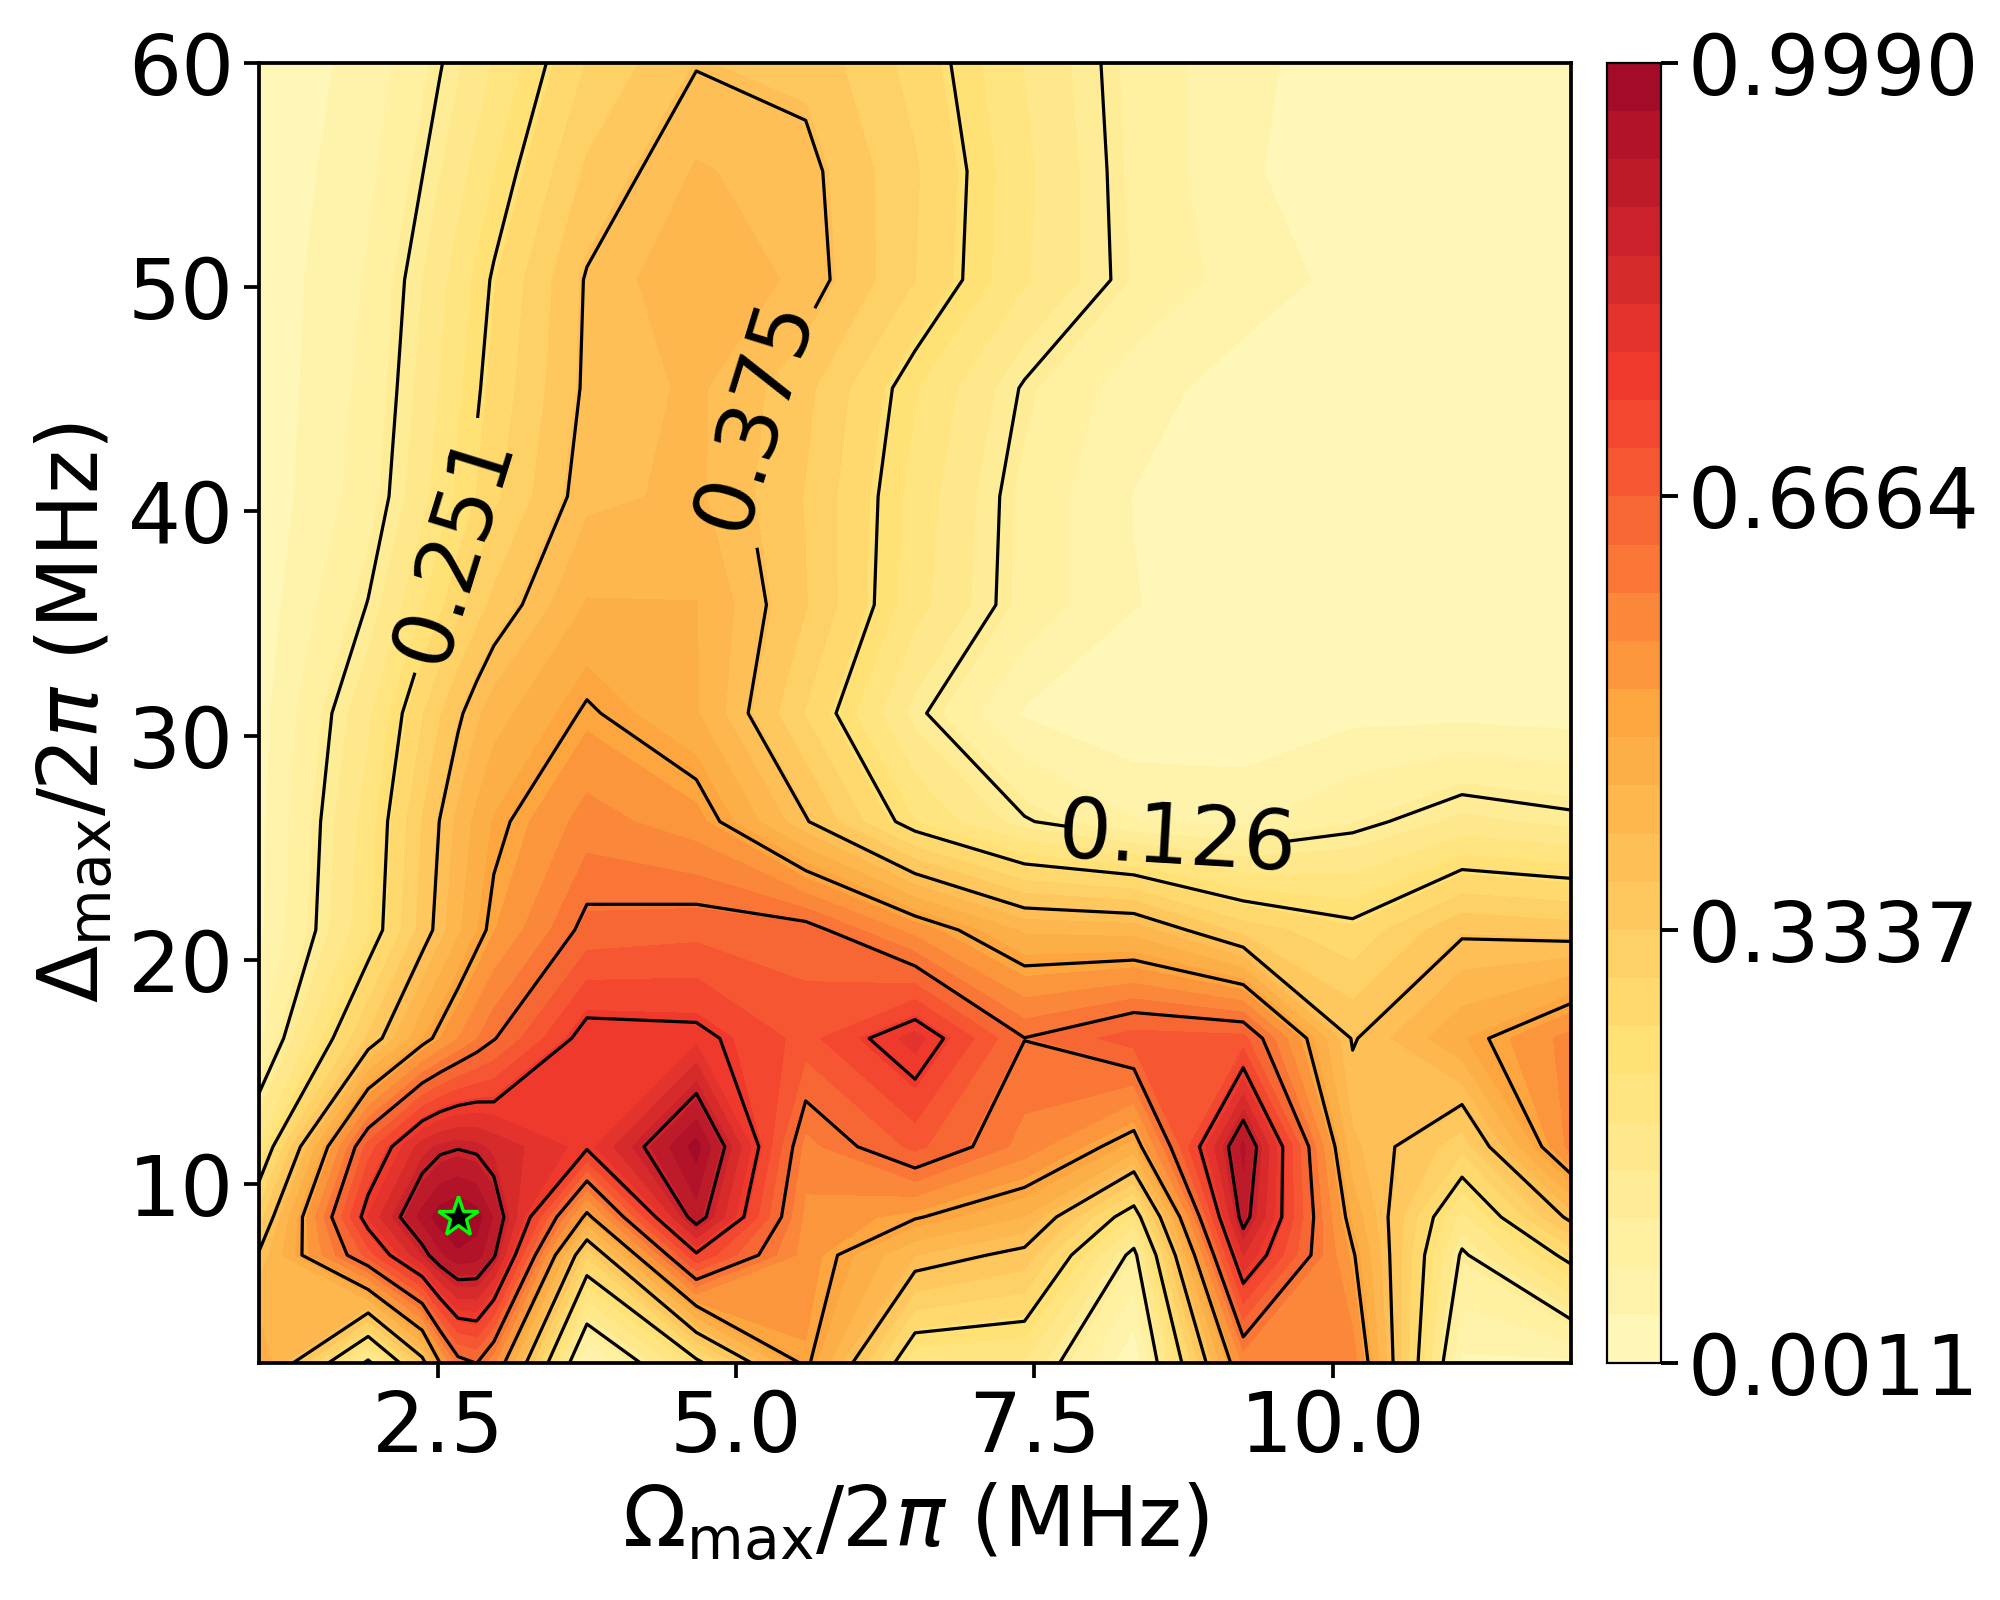
